# M03-2 | Reading the Annotations XNNPACKQuantizer Attaches

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m03_quantizer_api/02_read_annotations.ipynb)

The annotations in M03-1 were attached by hand: we chose the positions and we chose the specs. Before writing our own Quantizer, let's read what a real Quantizer attaches.
We use the test-version XNNPACKQuantizer from torchao (`torchao.testing.pt2e._xnnpack_quantizer`, an XNNPACK backend Quantizer torchao keeps for its own unit tests),
with the per-channel weight config.

To read each annotation, just answer three questions:

- **Position**: which input edge (`input_qspec_map`), or the output of which node (`output_qspec`).
- **Spec**: which `QuantizationSpec` (dtype, integer range, scheme, observer).
- **Present or not**: a position with no annotation, or whose spec is `None`, is not quantized.

This notebook reads three models:

- **A.** conv → relu: why there is no quantization point between conv and relu.
- **B.** residual: the two input edges of add, and when a conv has its own output annotation.
- **C.** cat_pool: which ops are left unannotated.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import the course's common/
    os.chdir(f"{repo}/en/m03_quantizer_api")

In [2]:
import copy

import torch

from common.graph_utils import qspec_summary, unannotated_ops
from common.models import example_inputs, get_model
from common.pt2e import ANNOTATION_KEY, Quantizer, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import annotation_notes, draw

quiet()
_ = torch.manual_seed(0)

## Getting the Graph the Quantizer Really Annotated

The most direct way is to call `quantizer.annotate(gm)` on the exported graph, but the graph you see that way differs from what the Quantizer actually annotated:
M03-1 listed the steps of `prepare_pt2e`, and BN is folded into conv **before** `annotate`. Also, as soon as `annotate` finishes, `prepare_pt2e` goes on to insert observers, which makes the annotations hard to read.

So we add a wrapper: `CaptureLabels` forwards every method to the inner Quantizer, and copies the graph only at the moment `annotate` finishes.


In [3]:
class CaptureLabels(Quantizer):
    def __init__(self, inner: Quantizer):
        self.inner = inner
        self.annotated: torch.fx.GraphModule | None = None

    def transform_for_annotation(self, model):
        return self.inner.transform_for_annotation(model)

    def annotate(self, model):
        self.inner.annotate(model)
        self.annotated = copy.deepcopy(model)  # the graph after annotation, before observers are inserted
        return model

    def validate(self, model):
        self.inner.validate(model)


def read_labels(model_name):
    """Run prepare_pt2e once on the given model and return the graph XNNPACKQuantizer annotated."""
    gm = export_module(get_model(model_name).eval(), example_inputs(4))
    xnnpack, _ = get_xnnpack_quantizer(is_per_channel=True)
    capture = CaptureLabels(xnnpack)
    prepare_pt2e(gm, capture)
    assert capture.annotated is not None
    return capture.annotated

In each of the three sections below, the annotations the Quantizer attached are written directly under each node in the graph: one line "edge upstream: spec" per input edge, and one line "output: spec" for the output.
Specs are abbreviated to dtype + granularity + scheme, e.g. `int8 per-tensor affine`; `not quantized` means the spec of that edge is `None`.

`annotation_notes(graph)` in the code is a small drawing helper of this project (`common/viz.py`), not a torchao API:
it reads each node's `node.meta["quantization_annotation"]`, turns it into the text above, and hands it to the `notes` parameter of `draw` to be drawn under the node.
To read the annotations, just look at the text in the graph.

## A. conv → relu: No Quantization Point Between conv and relu


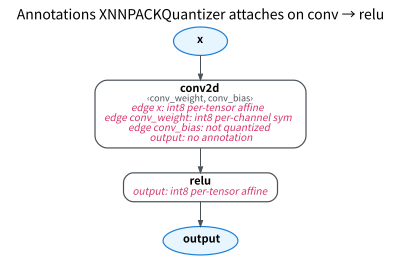

In [4]:
labeled = read_labels("conv_relu")
draw(labeled, notes=annotation_notes(labeled), title="Annotations XNNPACKQuantizer attaches on conv → relu")

Look at the four lines under conv2d:

- Three input edges: the activation `x`, the weight, and the bias. The activation is per-tensor affine, the weight is per-channel symmetric, and the bias spec is `None` (this config doesn't quantize the bias; it stays fp32).
- **The output of conv2d has no annotation; the output annotation is on relu**. So no observer is inserted between conv and relu, and the backend can treat conv + relu as one kernel. This is fusion in PT2E: it doesn't edit the graph, it just "doesn't annotate in the middle".

The full contents of the two specs (`common.graph_utils.qspec_summary`):


In [5]:
conv = next(n for n in labeled.graph.nodes if n.name == "conv2d")
ann = conv.meta[ANNOTATION_KEY]
# in the copied graph, the annotation keys are still node objects of the original graph, so look up by name
specs = {producer.name: spec for producer, spec in ann.input_qspec_map.items()}
x, weight, bias = (a.name for a in conv.args[:3])
print("activation:", qspec_summary(specs[x]).replace("\n", ", "))
print("weight:     ", qspec_summary(specs[weight]).replace("\n", ", "))

activation: int8 per-tensor affine [-128,127], HistogramObserver
weight:      int8 per-channel symmetric [-127,127], PerChannelMinMaxObserver, ch_axis=0


In [6]:
relu = next(n for n in labeled.graph.nodes if n.name == "relu")
assert ann.output_qspec is None and specs[bias] is None
assert relu.meta[ANNOTATION_KEY].output_qspec is not None

The activation uses `HistogramObserver`, and the weight uses `PerChannelMinMaxObserver` computing one scale per output channel (`ch_axis=0`); this is a choice made by this XNNPACKQuantizer default config (M02-1 compared the various observers).

## B. residual: The Two Input Edges of add


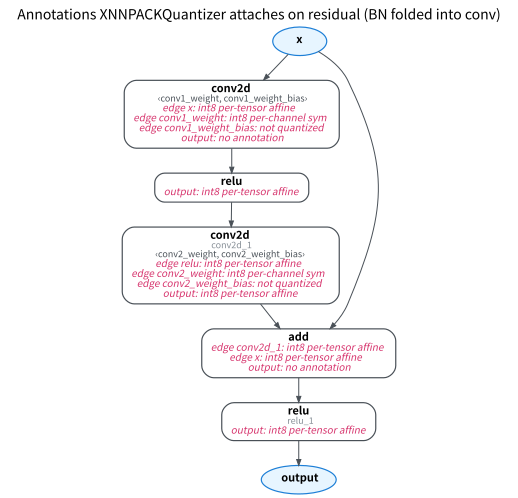

In [7]:
labeled = read_labels("residual")
draw(labeled, notes=annotation_notes(labeled), title="Annotations XNNPACKQuantizer attaches on residual (BN folded into conv)")

- There is no `batch_norm` in the graph anymore: the Quantizer sees the graph with BN already folded. The conv's weight has been replaced by the folded value, and the bias is the new constant computed while folding BN (`conv1_weight_bias`).
- Both input edges of `add` (`conv2d_1 → add`, `x → add`) have annotations, and the output annotation is on the following `relu_1`: add + relu is also treated as one pattern.
- The first conv is followed by a relu, so it has no output annotation; **the second conv (`conv2d_1`) is followed by an add, with no relu to fuse with, so it has its own output annotation**.

Same Quantizer, same op, yet different annotations: the Quantizer decides by looking at the op's context, not by mapping one op to one annotation.


In [8]:
anns = {n.name: n.meta.get(ANNOTATION_KEY) for n in labeled.graph.nodes}
assert "batch_norm" not in anns
assert anns["conv2d"].output_qspec is None and anns["conv2d_1"].output_qspec is not None
assert len(anns["add"].input_qspec_map) == 2 and anns["add"].output_qspec is None
assert anns["relu_1"].output_qspec is not None

## C. cat_pool: Which Ops Are Left Unannotated

An unannotated op doesn't raise an error; it just stays in fp32. Use `unannotated_ops` (`common.graph_utils`) to list ops with no annotation, and also mark them in the graph as "no annotation" (`annotation_notes` with `unlabeled=True`):


Ops without annotations: ['cat', 'max_pool2d']


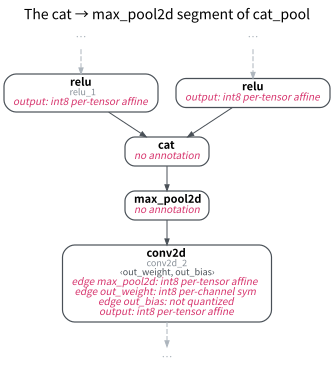

In [9]:
labeled = read_labels("cat_pool")
left = [n.name for n in unannotated_ops(labeled)]
print("Ops without annotations:", left)
draw(labeled, focus=["cat", "max_pool2d"], hops=1, notes=annotation_notes(labeled, unlabeled=True),
     title="The cat → max_pool2d segment of cat_pool")

In [10]:
assert {"cat", "max_pool2d"} <= set(left)

`cat` and `max_pool2d` are ops XNNPACK can quantize, yet they have no annotation. The cause was found in M01-2:

- The `cat` annotator in this torchao test version relies on `node.meta["source_fn_stack"]` to find the pattern. torch 2.14's export no longer fills this field, so it **fails silently**.
- The `max_pool2d` annotator itself isn't broken: its rule is "share qparams with the input", and since its input `cat` has no annotation, it goes unannotated too.

The executorch version of XNNPACKQuantizer doesn't have this problem (compared in M08-1).

Lesson: before using any Quantizer, draw its annotations and confirm that the ops you expect to be quantized really have annotations.
When writing your own Quantizer, finding ops by `node.target` is more stable than depending on metadata such as `source_fn_stack`; this is the approach of M03-3.

## Summary

- Each annotation answers only three things: position (edge or output), spec (`QuantizationSpec`), present or not.
- What fusion looks like in annotations: the nodes in the middle of a pattern get no output annotation, and the output annotation goes on the last op of the pattern (conv + relu on relu, add + relu on relu).
- The Quantizer sees the graph with BN folded and decides annotations from op context; unannotated ops raise no error, so you have to check yourself.
